In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plot
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


In [4]:
df = pd.read_csv("heart_disease.csv",na_values="?")
print(f"Rows and columns {df.shape}" )

Rows and columns (303, 14)


In [5]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [6]:
df = df.dropna()
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

In [7]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


age         0.222156
sex         0.226797
cp          0.404248
trestbps    0.159620
chol        0.066448
fbs         0.049040
restecg     0.184136
thalach    -0.420639
exang       0.391613
oldpeak     0.501461
slope       0.374689
ca          0.521178
thal        0.513377
num         1.000000
dtype: float64
thalach    -0.420639
fbs         0.049040
chol        0.066448
trestbps    0.159620
restecg     0.184136
age         0.222156
sex         0.226797
slope       0.374689
exang       0.391613
cp          0.404248
oldpeak     0.501461
thal        0.513377
ca          0.521178
num         1.000000
dtype: float64


Text(0.5, 1.0, 'Correlation between numerical values and target')

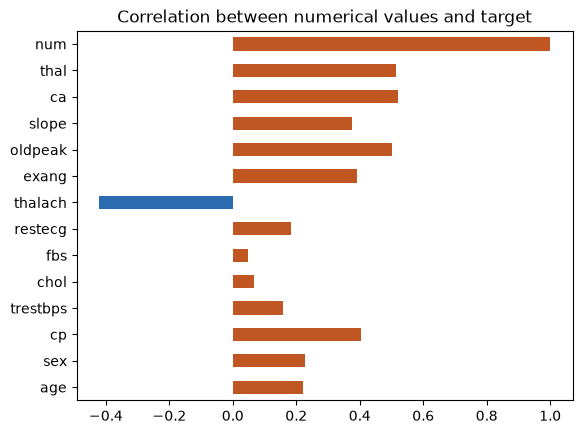

In [8]:
num = df.select_dtypes(include="number")

corr = num.corrwith(df["num"])
print(corr)
print(corr.sort_values())

corr.plot.barh(color=["#2b6cb0" if v < 0 else "#c05621" for v in corr])
plot.title("Correlation between numerical values and target")


Text(0.5, 1.0, 'Distribution of age')

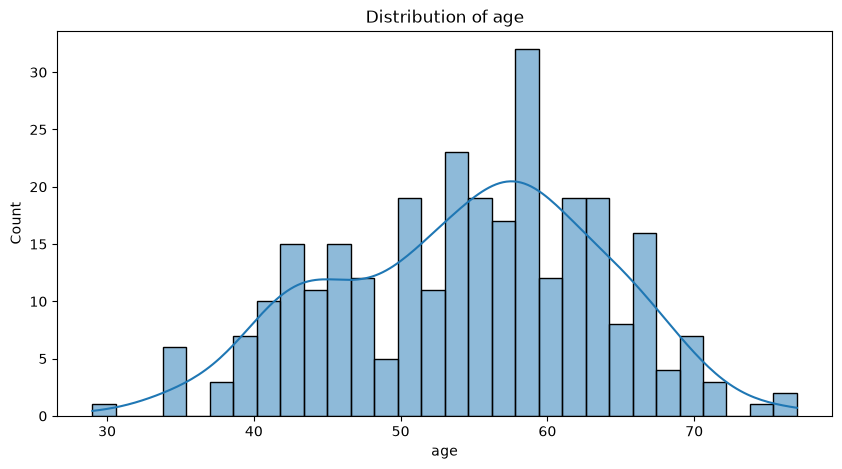

In [ ]:
plot.figure(figsize=(10,5))
sns.histplot(data=df,x="age",kde=True,bins=30)
plot.title("Distribution of age")

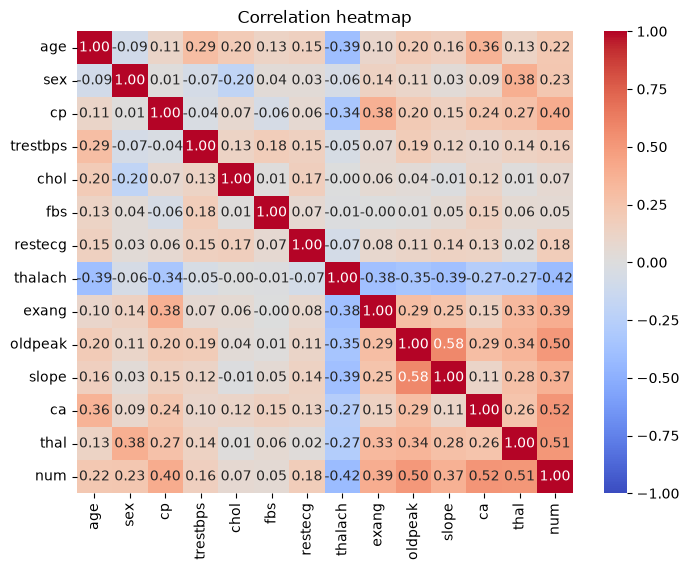

In [ ]:
plot.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0)
plot.title("Correlation heatmap")
plot.show()


In [10]:
df["target"] = (df["num"]>0).astype(int)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


In [11]:
X = df.drop(columns=["num","target"])
y= df["target"]

accuracy  = 0.867
recall    = 0.810
precision = 0.895
f1        = 0.850
              precision    recall  f1-score   support

           0       0.85      0.92      0.88        48
           1       0.89      0.81      0.85        42

    accuracy                           0.87        90
   macro avg       0.87      0.86      0.86        90
weighted avg       0.87      0.87      0.87        90



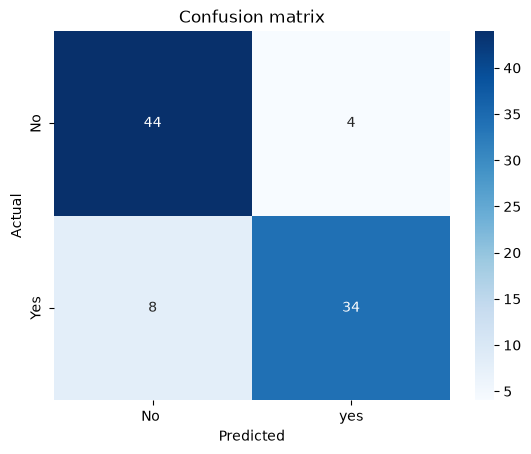

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix, classification_report)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.3, random_state=42)       # raw X, not X_scaled

preprocessor = StandardScaler()
model = Pipeline([
    ("preprocess", preprocessor),                            # scaling + one-hot, fitted on train only
    ("clf", SVC(kernel="linear", class_weight="balanced", C=0.01)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"accuracy  = {accuracy_score(y_test, y_pred):.3f}")
print(f"recall    = {recall_score(y_test, y_pred):.3f}")
print(f"precision = {precision_score(y_test, y_pred):.3f}")
print(f"f1        = {f1_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No ","yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.show()


TRAIN WITH DECISION TREE


cp          0.205360
age         0.179764
ca          0.164079
trestbps    0.105570
thal        0.097763
chol        0.063811
sex         0.057927
oldpeak     0.057870
restecg     0.018384
exang       0.013501
slope       0.013501
thalach     0.012241
fbs         0.010229
dtype: float64


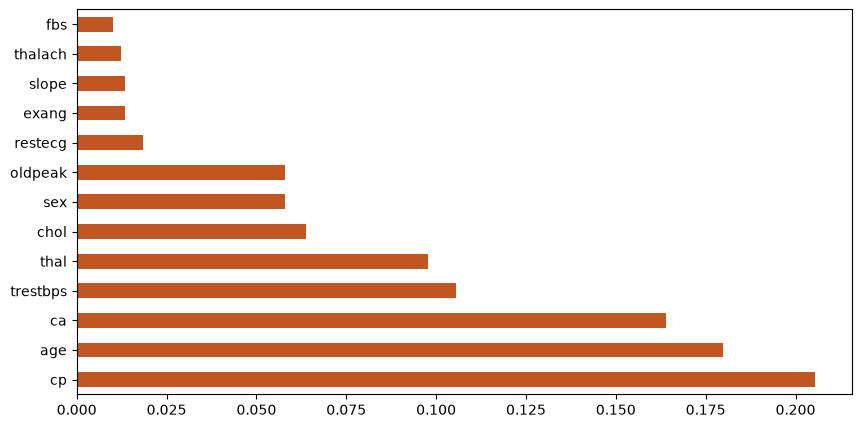

accuracy of the model:0.7555555555555555
classification report:              precision    recall  f1-score   support

           0       0.73      0.85      0.79        48
           1       0.79      0.64      0.71        42

    accuracy                           0.76        90
   macro avg       0.76      0.75      0.75        90
weighted avg       0.76      0.76      0.75        90



<Axes: >

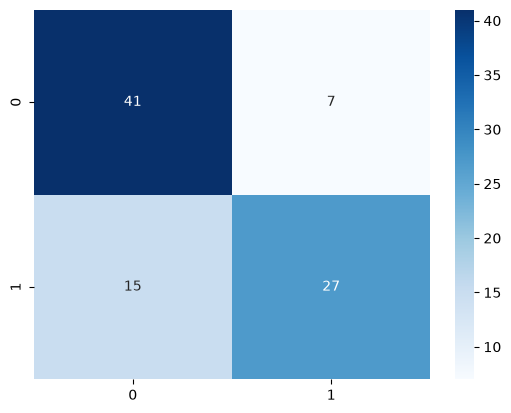

In [26]:
decision_tree = Pipeline([
    ("preprocess",preprocessor),
    ("clf",DecisionTreeClassifier(class_weight="balanced",random_state=42))
])


param_grid = {
    "clf__max_depth": [3, 5, 7, 10, None],
    "clf__min_samples_split": [2, 10, 20],
    "clf__min_samples_leaf": [1, 5, 10],
    "clf__criterion": ["gini", "entropy"],
}

model = GridSearchCV(
    estimator=decision_tree,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)


model.fit(X_train,y_train)

best_pipeline = model.best_estimator_
best_tree = best_pipeline.named_steps["clf"]

importance = pd.Series(
    best_tree.feature_importances_,
    index=X_train.columns,
).sort_values(ascending=False)

print(importance)
plot.figure(figsize=(10,5))

importance.plot.barh(color=["#2b6cb0" if v < 0 else "#c05621" for v in importance])
plot.show()

res = best_pipeline.predict(X_test)
accuracy = accuracy_score(y_test,res)
classification = classification_report(y_test,res)

print(f"accuracy of the model:{accuracy}")
print(f"classification report:{classification}")

conf_matrix = confusion_matrix(y_test,res)
sns.heatmap(conf_matrix,cmap="Blues",annot=True)